# Gordon's Map Data

Gordon has sent me some files of data. At first I thought that they were mapper data, but now I think that they are data Gordon extracted from Roger's model much as I extracted my data from my COMOL model.

I am going to start by looking at the on-axis one. The format is easy with an 8-line header giving the column names

and so the data can be loaded with numpy.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
g00 = np.loadtxt('GordonData/B_OnPath_y0.txt', skiprows=8, delimiter=',')
g00.shape

(155, 8)

 Let's start by looking at the by component vs. s. That should be informative.

 NOTE: I looked at the data a bit ahead of time and learned that the raw data call the main field -ve. I am going to reverse all the signs to make comparisons with my work easier.

Text(0.5, 1.0, "Measured Y field component (Gordon's map)")

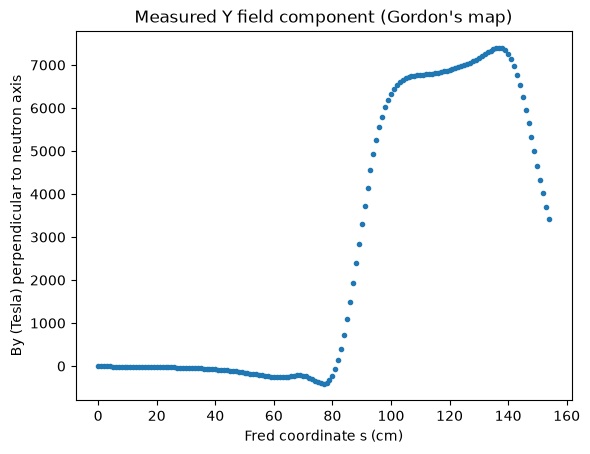

In [3]:
plt.plot(g00[:,7], -g00[:,4], '.')
plt.xlabel('Fred coordinate s (cm)')
plt.ylabel('By (Tesla) perpendicular to neutron axis')
plt.title('Measured Y field component (Gordon\'s map)')

So, with the sign corrected, this looks extremely like the predicted field corrected into the trap coordinate frame. The only difference that I see at a simple look is there is an extra wiggle in the field just before the sharp drop.

I presume that Bx is essentially zero?

Text(0.5, 1.0, "Measured X field component (Gordon's map)")

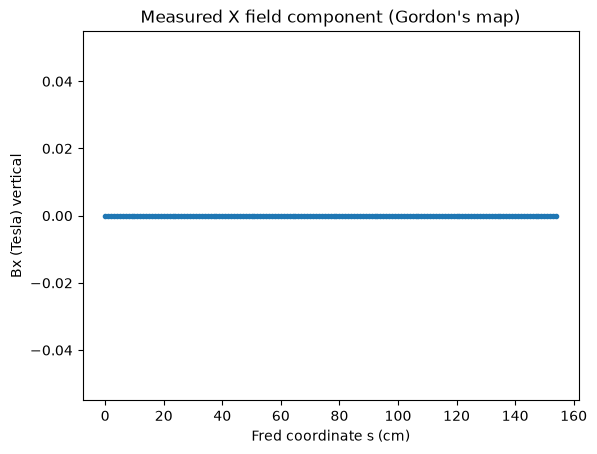

In [4]:
plt.plot(g00[:,7], -g00[:,3], '.')
plt.xlabel('Fred coordinate s (cm)')
plt.ylabel('Bx (Tesla) vertical')
plt.title('Measured X field component (Gordon\'s map)')

and then the z field

Text(0.5, 1.0, "Measured Z field component (Gordon's map)")

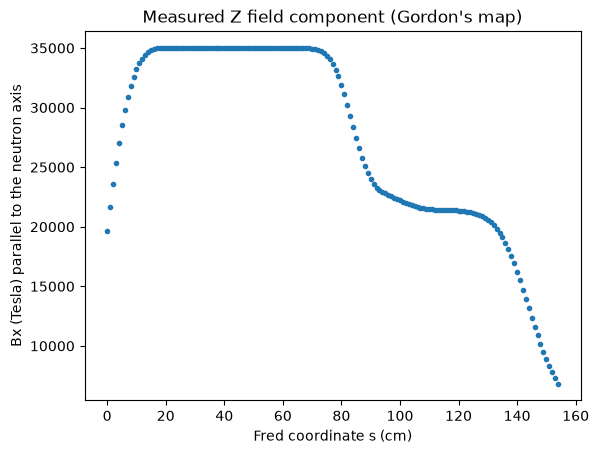

In [5]:
plt.plot(g00[:,7], -g00[:,5], '.')
plt.xlabel('Fred coordinate s (cm)')
plt.ylabel('Bx (Tesla) parallel to the neutron axis')
plt.title('Measured Z field component (Gordon\'s map)')

Yes, very much what one should expect. The minor differences from the model that I used, wuch as the decreased ripple in the trap region, are generally improvements and represent the final design tweaks that Cryogenic made to meet the final spec for the magnet. 

## Off axis data

Gordon did the |B| plot to generate this figure

![Gordon's |B| plot](GordonData/B_AlongPaths.png)

so we can add the $B_y$ plot.

In [6]:
g0m = np.loadtxt('GordonData/B_OnPath_y-4.txt', skiprows=8, delimiter=',')
g0p = np.loadtxt('GordonData/B_OnPath_y4.txt', skiprows=8, delimiter=',')

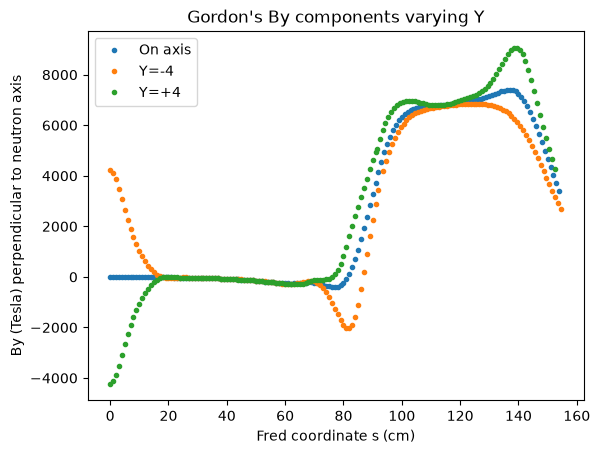

In [7]:
plt.plot(g00[:,7], -g00[:,4], '.', label='On axis')
plt.plot(g0m[:,7], -g0m[:,4], '.', label='Y=-4')
plt.plot(g0p[:,7], -g0p[:,4], '.', label='Y=+4')
plt.xlabel('Fred coordinate s (cm)')
plt.ylabel('By (Tesla) perpendicular to neutron axis')
plt.title('Gordon\'s By components varying Y')
plt.legend()

Well the shape is what we expect but the deviations are rather larger than I would expect. And that lead me to find that I had tranlated the tracks in my model by only 0.39 cm instead of 3.9 cm. This shows that the effects of going off axis scale roughly linearly with off-axis distance, at least out to 4 cm.

If this is really Roger's model data then this is as good as it gets. It says that my model was very close (which I think that we already knew) and that we are extracting the data in consistent ways. Now we just need Roshan's data.

## Field map

The one other thing that we can do with these data is to prepare a quiver plot showing the field lines along the tracks.

Text(0, 0.5, 'X (cm)')

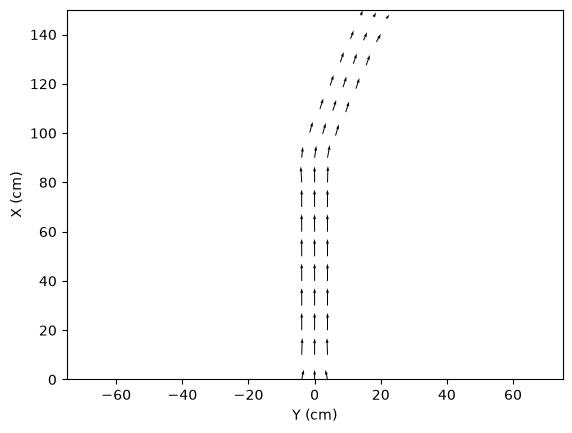

In [8]:
kink_idx = 855
irange = 20
step = 10
start = 0
stop = 155
mag=1000000
plt.quiver(g00[start:stop:step, 1], g00[start:stop:step, 2], 
           -g00[start:stop:step, 4], -g00[start:stop:step, 5],
           scale=mag, width=0.002)
plt.quiver(g0m[start:stop:step, 1], g0m[start:stop:step, 2], 
           -g0m[start:stop:step, 4], -g0m[start:stop:step, 5],
           scale=mag, width=0.002)
plt.quiver(g0p[start:stop:step, 1], g0p[start:stop:step, 2], 
           -g0p[start:stop:step, 4], -g0p[start:stop:step, 5],
           scale=mag, width=0.002)
plt.ylim(0, 150)
plt.xlim(-75, 75)
plt.xlabel('Y (cm)')
plt.ylabel('X (cm)')

and, as expected, that makes good sense.